# PipelinePrueba: PhysioNet/CinC Challenge 2019

### Predicción temprana de sepsis con series clínicas por hora

**Reproducción educativa del protocolo y la métrica del reto**, integrando evaluación, validación por paciente, ingeniería de atributos, manejo del desbalance, ajuste de umbral y Optuna.

**Fuente de los datos:** Reyna et al. (2019), *Early Prediction of Sepsis From Clinical Data: The PhysioNet/Computing in Cardiology Challenge 2019*. [Artículo](https://doi.org/10.1097/CCM.0000000000004145) · [Dataset, DOI versión 1.0.0](https://doi.org/10.13026/v64v-d857) · [Dataset, DOI latest](https://doi.org/10.13026/0y7p-s471).

> **Uso educativo:** este experimento no es un sistema clínico, no debe guiar atención médica y no reproduce una evaluación clínica prospectiva.

## ¿Qué vamos a reproducir?

El artículo describe el **reto de predicción temprana**, no un único modelo ganador ni una receta de hiperparámetros. Reproduciremos su encuadre: una predicción por hora y paciente, el conjunto público de entrenamiento de dos cohortes hospitalarias y la **utilidad clínica temporal normalizada** del evaluador oficial. Entrenaremos y compararemos modelos didácticos; no afirmaremos replicar las puntuaciones de participantes ni la clasificación en el test oculto.

El reto usa la definición Sepsis-3 y premia anticipar el inicio clínico: la ventana de predicción útil va de 12 horas antes a 3 horas después, con recompensa máxima 6 horas antes. Penaliza falsas alarmas y detecciones tardías o ausentes. Los datos se publican como archivos horarios `PSV`, uno por paciente, con variables clínicas y `SepsisLabel`.

El test oficial de la competencia no es público. Aquí usaremos `training_setA` para desarrollo y reservaremos `training_setB` como **cohorte pública externa**. Aunque esa separación ayuda a estudiar generalización entre cohortes, no sustituye al test oculto del reto.

## Plan de trabajo

1. Preparar entorno, descargar los archivos públicos si aún no existen y verificar su estructura.
2. Describir etiquetas, pacientes, faltantes y desbalance, conservando al paciente como unidad de separación.
3. Crear atributos temporales causales y separar desarrollo/validación por paciente.
4. Comparar un modelo base y `class_weight`; seleccionar atributos solo con entrenamiento.
5. Optimizar hiperparámetros mediante CV agrupada y utilidad clínica.
6. Elegir el umbral en validación, evaluar una única vez en la cohorte B y guardar reporte/modelo/configuración.

**Prevención de leakage:** ninguna fila del mismo paciente aparece en más de una partición; validación y cohorte B no participan en el ajuste ni en la selección de variables.

In [1]:
# Importamos análisis, modelos, validación, visualización y descarga desde la biblioteca estándar.
%matplotlib inline
import json
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from html.parser import HTMLParser
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import Pipeline

# Fijamos el estilo y hacemos reproducibles las particiones.
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
SEED = 42

# Encontramos la raíz del proyecto independientemente de dónde se abra Jupyter.
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
        if (candidate / "notebooks").is_dir() and (candidate / "data").is_dir()
    ),
    Path.cwd().resolve(),
)
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "physionet_challenge_2019"
REPORTS_DIR = PROJECT_ROOT / "reports" / "physionet_challenge_2019"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in (DATA_DIR, REPORTS_DIR, FIGURES_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Parámetros de cómputo: aumentar trials/pliegues solo si el equipo tiene recursos.
N_SPLITS = 3
N_TRIALS = 8
MAX_SEARCH_PATIENTS = 6000
TOP_K_FEATURES = 20
print(f"Proyecto: {PROJECT_ROOT}")
print(f"Datos: {DATA_DIR}")

Proyecto: C:\Users\marco\ml-demo1-profesor
Datos: C:\Users\marco\ml-demo1-profesor\data\raw\physionet_challenge_2019


## Descarga reproducible de los datos

Los archivos de entrenamiento se obtienen del directorio público oficial de PhysioNet; el conjunto completo tiene unos 40 mil archivos por paciente. La primera ejecución puede tardar según la conexión. El código descarga únicamente archivos ausentes, valida que el contenido sea un `PSV` y escribe primero a un archivo temporal para poder reanudar sin conservar descargas parciales.

La licencia del dataset es [ODbL](https://physionet.org/content/challenge-2019/1.0.0/). Conserva la atribución indicada en la portada si reutilizas los datos.

In [2]:
# Descargamos training_setA/B solo cuando la carpeta local todavía está incompleta.
PHYSIONET_BASE = "https://physionet.org/files/challenge-2019/1.0.0/training"


class PSVLinkParser(HTMLParser):
    """Extrae enlaces a archivos PSV del índice HTML de PhysioNet."""

    def __init__(self):
        super().__init__()
        self.files = []

    def handle_starttag(self, tag, attrs):
        if tag == "a":
            href = dict(attrs).get("href", "")
            if href.lower().endswith(".psv"):
                self.files.append(href)


def fetch_bytes(url):
    """Descarga una URL y reintenta errores de red transitorios con espera creciente."""
    for attempt in range(5):
        request = Request(url, headers={"User-Agent": "PipelinePrueba educational reproduction"})
        try:
            with urlopen(request, timeout=90) as response:
                return response.read()
        except HTTPError as error:
            if error.code not in (429, 500, 502, 503, 504) or attempt == 4:
                raise
        except (TimeoutError, URLError, ConnectionError):
            if attempt == 4:
                raise
        time.sleep(2 ** attempt)
    raise RuntimeError(f"No se pudo descargar {url} tras varios intentos.")


def descargar_cohorte(nombre_cohorte, max_workers=12):
    """Descarga los PSV ausentes de una cohorte y valida sus encabezados."""
    index_url = f"{PHYSIONET_BASE}/{nombre_cohorte}/"
    parser = PSVLinkParser()
    parser.feed(fetch_bytes(index_url).decode("utf-8", errors="replace"))
    if not parser.files:
        raise RuntimeError(f"No se encontraron enlaces PSV en {index_url}")

    destino = DATA_DIR / nombre_cohorte
    destino.mkdir(parents=True, exist_ok=True)
    pendientes = [
        (f"{index_url}{filename}", destino / filename)
        for filename in parser.files
        if not (destino / filename).exists()
    ]
    if not pendientes:
        print(f"{nombre_cohorte}: {len(parser.files):,} archivos ya disponibles.")
        return len(parser.files)

    errores = []
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        futures = {
            pool.submit(fetch_bytes, url): (url, path)
            for url, path in pendientes
        }
        for numero, future in enumerate(as_completed(futures), start=1):
            url, path = futures[future]
            try:
                contenido = future.result()
                if not contenido.startswith(b"HR|") or b"SepsisLabel" not in contenido.splitlines()[0]:
                    raise ValueError(f"El archivo recibido no parece PSV: {url}")
                temporal = path.with_suffix(path.suffix + ".part")
                temporal.write_bytes(contenido)
                temporal.replace(path)
            except Exception as error:
                errores.append((url, repr(error)))
            if numero % 2000 == 0 or numero == len(pendientes):
                print(f"{nombre_cohorte}: {numero:,}/{len(pendientes):,}; errores={len(errores)}")

    if errores:
        raise RuntimeError(f"Falló la descarga de {len(errores)} archivos; ejemplo: {errores[:3]}")
    return len(parser.files)


for split_name in ("training_setA", "training_setB"):
    descargar_cohorte(split_name)
print("Descarga/verificación de archivos finalizada.")

training_setA: 20,336 archivos ya disponibles.
training_setB: 20,000 archivos ya disponibles.
Descarga/verificación de archivos finalizada.


## Comprender una observación

Cada fila es una hora de estancia en UCI; cada paciente contribuye una serie de longitud variable. `SepsisLabel` puede permanecer en 1 durante las horas posteriores al inicio, por lo que miles de filas no equivalen a miles de pacientes independientes.

Las variables demográficas constantes por paciente, valores ausentes y medidas horarias se conservarán. El identificador y la cohorte sirven para agrupar y evaluar; **nunca** se usan como predictores.

In [3]:
# Leemos cada paciente una vez y añadimos metadatos de agrupación fuera de las features.
def cargar_cohorte(nombre_cohorte, codigo_cohorte, patient_offset):
    """Carga los PSV de una cohorte; devuelve filas y un identificador entero por paciente."""
    archivos = sorted((DATA_DIR / nombre_cohorte).glob("*.psv"))
    if not archivos:
        raise FileNotFoundError(f"No hay archivos PSV en {DATA_DIR / nombre_cohorte}")
    pacientes = []
    for patient_code, path in enumerate(archivos, start=1):
        frame = pd.read_csv(path, sep="|", dtype=np.float32)
        if "SepsisLabel" not in frame.columns:
            raise ValueError(f"Falta SepsisLabel en {path}")
        frame["PatientID"] = np.int32(patient_offset + patient_code)
        frame["CohortCode"] = np.int8(codigo_cohorte)
        pacientes.append(frame)
        if patient_code % 5000 == 0 or patient_code == len(archivos):
            print(f"{nombre_cohorte}: {patient_code:,}/{len(archivos):,} pacientes leídos")
    return pd.concat(pacientes, ignore_index=True)


# A y B reciben códigos de paciente independientes para impedir colisiones de ID.
inicio = time.time()
data_a = cargar_cohorte("training_setA", 0, 0)
data_b = cargar_cohorte("training_setB", 1, 100_000)
data = pd.concat([data_a, data_b], ignore_index=True)
del data_a, data_b
print(f"Filas: {len(data):,}; columnas: {data.shape[1]}")
print(f"Tiempo de lectura: {(time.time() - inicio) / 60:.1f} min")
print("Ejemplo de estructura:")
display(data.head())
print("Archivos por cohorte:", {
    name: len(list((DATA_DIR / name).glob("*.psv")))
    for name in ("training_setA", "training_setB")
})

training_setA: 5,000/20,336 pacientes leídos
training_setA: 10,000/20,336 pacientes leídos
training_setA: 15,000/20,336 pacientes leídos
training_setA: 20,000/20,336 pacientes leídos
training_setA: 20,336/20,336 pacientes leídos
training_setB: 5,000/20,000 pacientes leídos
training_setB: 10,000/20,000 pacientes leídos
training_setB: 15,000/20,000 pacientes leídos
training_setB: 20,000/20,000 pacientes leídos
Filas: 1,552,210; columnas: 43
Tiempo de lectura: 2.6 min
Ejemplo de estructura:


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,PatientID,CohortCode
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,1.0,0.0,1,0
1,97.0,95.0,NaN,98.0,75.330002,NaN,19.0,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,2.0,0.0,1,0
2,89.0,99.0,NaN,122.0,86.000000,NaN,22.0,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,3.0,0.0,1,0
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,4.0,0.0,1,0
4,103.0,88.5,NaN,122.0,91.330002,NaN,24.5,NaN,NaN,NaN,...,NaN,83.139999,0.0,NaN,NaN,-0.03,5.0,0.0,1,0


Archivos por cohorte: {'training_setA': 20336, 'training_setB': 20000}


## Revisión inicial y desbalance

Antes de modelar, contamos pacientes con sepsis y observaciones positivas por cohorte, además de examinar faltantes. La unidad de evaluación de la utilidad será el paciente; las métricas de clasificación por hora se reportan como información complementaria, porque una accuracy alta puede ocultar la baja prevalencia.

In [4]:
# Resumimos prevalencia por paciente y cohorte sin mezclar filas como unidades independientes.
patient_summary = (
    data.groupby(["CohortCode", "PatientID"], sort=False)["SepsisLabel"]
    .max()
    .rename("Septic")
    .reset_index()
)
resumen_cohortes = (
    patient_summary.groupby("CohortCode")["Septic"]
    .agg(pacientes="size", pacientes_con_sepsis="sum", prevalencia="mean")
    .rename(index={0: "training_setA", 1: "training_setB"})
)
display(resumen_cohortes)
print("Tasa de etiquetas positivas por hora:", f"{data['SepsisLabel'].mean():.3%}")
print("Valores faltantes por variable (primeras 15):")
display(data.drop(columns=["PatientID", "CohortCode"]).isna().mean().sort_values(ascending=False).head(15))

# Calculamos la duración de estancia y el inicio de sepsis por paciente para contextualizar series.
duracion = data.groupby("PatientID", sort=False).size()
primer_evento = data.loc[data["SepsisLabel"].eq(1)].groupby("PatientID", sort=False).head(1)
print(f"Horas por paciente, mediana: {duracion.median():.0f}; p95: {duracion.quantile(.95):.0f}")
print(f"Pacientes con al menos una etiqueta positiva: {patient_summary['Septic'].sum():,}")

,pacientes,pacientes_con_sepsis,prevalencia
CohortCode,,,
training_setA,20336,1790.0,0.088021
training_setB,20000,1142.0,0.057100


Tasa de etiquetas positivas por hora: 1.798%
Valores faltantes por variable (primeras 15):


Bilirubin_direct    0.998074
Fibrinogen          0.993402
TroponinI           0.990477
Bilirubin_total     0.985092
Alkalinephos        0.983932
AST                 0.983776
Lactate             0.973299
PTT                 0.970559
SaO2                0.965494
EtCO2               0.962868
Phosphate           0.959863
HCO3                0.958106
Chloride            0.954603
BaseExcess          0.945790
PaCO2               0.944401
dtype: float64

Horas por paciente, mediana: 38; p95: 58
Pacientes con al menos una etiqueta positiva: 2,932.0


## Métrica principal: utilidad clínica del reto

Para cada paciente séptico, el evaluador asigna recompensa máxima a una alerta 6 horas antes del primer `SepsisLabel`; recompensa linealmente menor entre −12 y −6 horas y entre −6 y +3 horas. Alertas en pacientes no sépticos tienen utilidad −0.05; los verdaderos negativos, 0. La utilidad se suma por paciente y se normaliza contra una política de no alertar y una secuencia ideal.

También informaremos AUROC, AUPRC, F1, precision, recall y accuracy sobre observaciones horarias. Estas no reemplazan la métrica clínica. La implementación siguiente sigue los parámetros documentados en el [evaluador oficial](https://github.com/physionetchallenges/evaluation-2019); cite el reto/dataset al reutilizarla.

In [5]:
# Codificamos la utilidad temporal por paciente y la normalizamos como en el evaluador.
DT_EARLY, DT_OPTIMAL, DT_LATE = -12, -6, 3
MAX_UTILITY_TP, MIN_UTILITY_FN = 1.0, -2.0
UTILITY_FP, UTILITY_TN = -0.05, 0.0


def utilidad_paciente(labels, predictions):
    """Calcula utilidad temporal de un paciente con la ventana del Challenge 2019."""
    labels = np.asarray(labels, dtype=np.int8)
    predictions = np.asarray(predictions, dtype=np.int8)
    if labels.ndim != 1 or predictions.shape != labels.shape:
        raise ValueError("Labels y predicciones deben ser vectores de igual longitud.")
    if not np.isin(labels, [0, 1]).all() or not np.isin(predictions, [0, 1]).all():
        raise ValueError("Labels y predicciones solo pueden contener 0 o 1.")

    tiempo = np.arange(len(labels))
    utility = np.zeros(len(labels), dtype=np.float64)
    if not labels.any():
        utility[predictions == 1] = UTILITY_FP
        return float(utility.sum())

    inicio_sepsis = int(np.flatnonzero(labels)[0])
    tiempo_optimo = inicio_sepsis - DT_OPTIMAL
    ventana_early = tiempo <= tiempo_optimo + DT_OPTIMAL
    ventana_late = (tiempo > tiempo_optimo + DT_OPTIMAL) & (
        tiempo <= tiempo_optimo + DT_LATE
    )
    tp_early = (predictions == 1) & ventana_early
    tp_late = (predictions == 1) & ventana_late
    fn_late = (predictions == 0) & ventana_late

    m1 = MAX_UTILITY_TP / (DT_OPTIMAL - DT_EARLY)
    b1 = -m1 * DT_EARLY
    m2 = -MAX_UTILITY_TP / (DT_LATE - DT_OPTIMAL)
    b2 = -m2 * DT_LATE
    m3 = MIN_UTILITY_FN / (DT_LATE - DT_OPTIMAL)
    b3 = -m3 * DT_OPTIMAL
    utility[tp_early] = np.maximum(
        m1 * (tiempo[tp_early] - tiempo_optimo) + b1, UTILITY_FP
    )
    utility[tp_late] = m2 * (tiempo[tp_late] - tiempo_optimo) + b2
    utility[fn_late] = m3 * (tiempo[fn_late] - tiempo_optimo) + b3
    return float(utility.sum())


def evaluar_reto(labels, probabilities, patient_ids, threshold=0.5):
    """Devuelve métricas horarias y utilidad normalizada agregada por paciente."""
    labels = np.asarray(labels, dtype=np.int8)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    patient_ids = np.asarray(patient_ids)
    if not (len(labels) == len(probabilities) == len(patient_ids)):
        raise ValueError("Labels, probabilidades e IDs deben tener la misma longitud.")
    predictions = (probabilities >= threshold).astype(np.int8)

    boundaries = np.flatnonzero(patient_ids[1:] != patient_ids[:-1]) + 1
    starts = np.r_[0, boundaries]
    ends = np.r_[boundaries, len(labels)]
    utility_observed = 0.0
    utility_inaction = 0.0
    utility_best = 0.0
    for start, end in zip(starts, ends):
        patient_labels = labels[start:end]
        patient_predictions = predictions[start:end]
        utility_observed += utilidad_paciente(patient_labels, patient_predictions)
        utility_inaction += utilidad_paciente(
            patient_labels, np.zeros(end - start, dtype=np.int8)
        )
        best_predictions = np.zeros(end - start, dtype=np.int8)
        if patient_labels.any():
            onset = int(np.flatnonzero(patient_labels)[0])
            t_sepsis = onset - DT_OPTIMAL
            left = max(0, t_sepsis + DT_EARLY)
            right = min(t_sepsis + DT_LATE + 1, end - start)
            best_predictions[left:right] = 1
        utility_best += utilidad_paciente(patient_labels, best_predictions)

    denominator = utility_best - utility_inaction
    normalized_utility = (
        (utility_observed - utility_inaction) / denominator
        if denominator != 0
        else np.nan
    )
    result = {
        "utility_normalized": float(normalized_utility),
        "utility_observed": float(utility_observed),
        "utility_inaction": float(utility_inaction),
        "utility_best": float(utility_best),
        "threshold": float(threshold),
        "accuracy": float(accuracy_score(labels, predictions)),
        "f1": float(f1_score(labels, predictions, zero_division=0)),
        "precision": float(precision_score(labels, predictions, zero_division=0)),
        "recall": float(recall_score(labels, predictions, zero_division=0)),
        "auroc": float(roc_auc_score(labels, probabilities)) if np.unique(labels).size == 2 else np.nan,
        "auprc": float(average_precision_score(labels, probabilities)) if labels.any() else np.nan,
    }
    return result, predictions


# Pruebas pequeñas confirman que los casos de referencia se comportan como esperamos.
assert utilidad_paciente([0, 0, 0, 0, 1, 1], [0, 0, 1, 1, 1, 1]) > 0
assert utilidad_paciente([0, 0, 0], [0, 0, 0]) == 0
print("Pruebas básicas de la métrica aprobadas.")

Pruebas básicas de la métrica aprobadas.


## Separación por pacientes y atributos temporales

El conjunto A se separa en entrenamiento y validación estratificando por presencia de sepsis **a nivel paciente**. El conjunto B se mantiene intacto como evaluación externa. Las variables derivadas incluyen razones clínicas sencillas, diferencias de una hora y medias móviles de seis horas; usan solo la historia disponible hasta la hora actual, nunca datos futuros ni `SepsisLabel`.

El imputador de medianas se ajustará dentro del pipeline de cada pliegue, por lo que no aprende estadísticas de validación o B.

In [6]:
# Añadimos variables clínicas derivadas en orden temporal y exclusivamente por paciente.
data["ShockIndex"] = data["HR"] / data["SBP"].replace(0, np.nan)
data["PulsePressure"] = data["SBP"] - data["DBP"]
for signal in ("HR", "MAP", "Resp", "O2Sat"):
    grouped_signal = data.groupby("PatientID", sort=False)[signal]
    data[f"{signal}_delta_1h"] = grouped_signal.diff()
    data[f"{signal}_mean_6h"] = grouped_signal.transform(
        lambda values: values.rolling(window=6, min_periods=1).mean()
    )

# Separamos pacientes de la cohorte A; el conjunto B queda como evaluación externa.
summary_a = patient_summary.loc[patient_summary["CohortCode"].eq(0)].copy()
ids_train, ids_val = train_test_split(
    summary_a["PatientID"].to_numpy(),
    test_size=0.20,
    random_state=SEED,
    stratify=summary_a["Septic"].to_numpy(),
)
assert set(ids_train).isdisjoint(ids_val)
mask_a = data["CohortCode"].eq(0)
mask_b = data["CohortCode"].eq(1)
mask_train = mask_a & data["PatientID"].isin(ids_train)
mask_val = mask_a & data["PatientID"].isin(ids_val)
mask_test = mask_b

excluded = {"SepsisLabel", "PatientID", "CohortCode"}
feature_cols = [column for column in data.columns if column not in excluded]
X_train = data.loc[mask_train, feature_cols].astype(np.float32)
y_train = data.loc[mask_train, "SepsisLabel"].astype(np.int8)
groups_train = data.loc[mask_train, "PatientID"].to_numpy()
X_val = data.loc[mask_val, feature_cols].astype(np.float32)
y_val = data.loc[mask_val, "SepsisLabel"].astype(np.int8)
groups_val = data.loc[mask_val, "PatientID"].to_numpy()
X_test = data.loc[mask_test, feature_cols].astype(np.float32)
y_test = data.loc[mask_test, "SepsisLabel"].astype(np.int8)
groups_test = data.loc[mask_test, "PatientID"].to_numpy()

assert set(ids_train).isdisjoint(np.unique(groups_test))
assert set(ids_val).isdisjoint(np.unique(groups_test))

# Liberamos las tablas concatenadas y máscaras; basta con las particiones y resumen de pacientes.
del data, patient_summary, mask_a, mask_b, mask_train, mask_val, mask_test

print(f"Pacientes: train={len(np.unique(groups_train)):,}, validación={len(np.unique(groups_val)):,}, cohorte B={len(np.unique(groups_test)):,}")
print(f"Observaciones horarias: train={len(y_train):,}, validación={len(y_val):,}, cohorte B={len(y_test):,}")
print(f"Features: {len(feature_cols)}; positivos por hora en train: {y_train.mean():.3%}")

Pacientes: train=16,268, validación=4,068, cohorte B=20,000
Observaciones horarias: train=631,120, validación=159,095, cohorte B=761,995
Features: 50; positivos por hora en train: 2.172%


## Modelo base y class weight

Usamos `HistGradientBoostingClassifier`, un modelo de árboles que maneja interacciones no lineales y funciona con faltantes después de imputación. El baseline no ponderado establece referencia; `class_weight='balanced'` eleva la penalización de la clase positiva. Ambos se ajustan solo con pacientes de entrenamiento y se comparan en la misma validación.

El modelo genera una probabilidad por hora. La regla 0.5 es solo una referencia inicial; todavía no la consideramos una decisión clínica.

No aplicamos SMOTE por defecto: interpolar filas horarias ignorando paciente y tiempo puede crear fisiología sintética incoherente y romper la estructura longitudinal. En este reto priorizamos `class_weight` y evaluación agrupada.

In [7]:
# Creamos una función para mantener el mismo preprocesamiento y semilla en todos los modelos.
def crear_modelo(parametros=None, class_weight=None):
    """Construye un pipeline de imputación y HistGradientBoosting reproducible."""
    parametros = {} if parametros is None else dict(parametros)
    clasificador = HistGradientBoostingClassifier(
        class_weight=class_weight,
        random_state=SEED,
        early_stopping=False,
        **parametros,
    )
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("model", clasificador),
        ]
    )


def probabilidad_positiva(modelo, X):
    """Extrae probabilidad de sepsis y valida su forma/rango."""
    probabilities = modelo.predict_proba(X)[:, 1]
    if not np.isfinite(probabilities).all():
        raise ValueError("El modelo produjo probabilidades no finitas.")
    return np.clip(probabilities, 0.0, 1.0)


# Entrenamos dos referencias y comparamos utilidad/F1 en la validación de pacientes.
modelos_validacion = {}
metricas_validacion = {}
for nombre, pesos in (("base", None), ("class_weight", "balanced")):
    modelo = crear_modelo({"max_iter": 120, "learning_rate": 0.1, "max_leaf_nodes": 31}, pesos)
    modelo.fit(X_train, y_train)
    probabilities = probabilidad_positiva(modelo, X_val)
    metricas, _ = evaluar_reto(y_val, probabilities, groups_val, threshold=0.5)
    modelos_validacion[nombre] = modelo
    metricas_validacion[nombre] = metricas
    print(nombre, {key: round(value, 4) for key, value in metricas.items() if key in ("utility_normalized", "f1", "auprc", "recall")})


base {'utility_normalized': 0.0247, 'f1': 0.0474, 'recall': 0.0289, 'auprc': 0.0937}
class_weight {'utility_normalized': 0.3792, 'f1': 0.1239, 'recall': 0.6112, 'auprc': 0.1035}


## Selección de variables (solo entrenamiento)

La selección puede reducir costo y ruido, pero las variables raras de laboratorio pueden ser relevantes. Usamos importancias de un Extra Trees con `class_weight='balanced'`, ajustado a una muestra de filas de entrenamiento; ni validación ni cohorte B participan en el ranking. Conservamos las 20 variables mejor puntuadas y luego comprobamos si realmente mejoran la utilidad.

In [8]:
# Ajustamos un selector embedded en una muestra reproducible del conjunto de entrenamiento.
selector_rows = X_train.sample(
    n=min(100_000, len(X_train)), random_state=SEED
).index
selector_imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_selector = selector_imputer.fit_transform(X_train.loc[selector_rows])
selector = ExtraTreesClassifier(
    n_estimators=80,
    max_depth=16,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
selector.fit(X_selector, y_train.loc[selector_rows])
importancias = pd.Series(
    selector.feature_importances_, index=feature_cols
).sort_values(ascending=False)
selected_features = importancias.head(min(TOP_K_FEATURES, len(feature_cols))).index.tolist()
print("Atributos seleccionados:")
display(importancias.head(TOP_K_FEATURES).to_frame("importancia"))

# Evaluamos el subconjunto en validación; una mejora debe reflejarse en la métrica principal.
modelo_seleccion = crear_modelo(
    {"max_iter": 120, "learning_rate": 0.1, "max_leaf_nodes": 31},
    class_weight="balanced",
)
modelo_seleccion.fit(X_train[selected_features], y_train)
prob_seleccion_val = probabilidad_positiva(
    modelo_seleccion, X_val[selected_features]
)
metricas_seleccion, _ = evaluar_reto(
    y_val, prob_seleccion_val, groups_val, threshold=0.5
)
metricas_validacion["feature_selection"] = metricas_seleccion
print("Utilidad normalizada con features seleccionadas:", round(metricas_seleccion["utility_normalized"], 4))

Atributos seleccionados:


,importancia
ICULOS,0.280205
HR_mean_6h,0.055947
Unit2,0.051717
Resp_mean_6h,0.047549
Unit1,0.043462
HR,0.037880
Resp,0.037079
ShockIndex,0.028472
Temp,0.028389
Age,0.024953


Utilidad normalizada con features seleccionadas: 0.3794


## Validación cruzada agrupada y Optuna

La búsqueda usa `StratifiedGroupKFold`: todas las horas de un paciente quedan en un solo pliegue, y se intenta preservar el balance de la clase por hora. Para que la búsqueda sea asequible, Optuna usa hasta 6,000 pacientes seleccionados solo de entrenamiento; al final el modelo ganador se vuelve a ajustar con todos los pacientes de entrenamiento.

Cada trial maximiza la utilidad normalizada media de los pliegues a umbral 0.5. El umbral se ajusta después con validación, manteniendo el objetivo y la decisión final claramente separados. Los resultados son experimentales; deben reportarse junto con la cohorte y el split.

In [9]:
# Seleccionamos pacientes de búsqueda estratificados por etiqueta de paciente.
summary_train = summary_a.loc[summary_a["PatientID"].isin(ids_train)]
if len(summary_train) <= MAX_SEARCH_PATIENTS:
    search_ids = summary_train["PatientID"].to_numpy()
else:
    search_ids, _ = train_test_split(
        summary_train["PatientID"].to_numpy(),
        train_size=MAX_SEARCH_PATIENTS,
        random_state=SEED,
        stratify=summary_train["Septic"].to_numpy(),
    )
search_mask = pd.Series(groups_train, index=X_train.index).isin(search_ids).to_numpy()
X_search = X_train.loc[search_mask, selected_features]
y_search = y_train.loc[search_mask]
groups_search = groups_train[search_mask]
print(f"CV Optuna: {len(search_ids):,} pacientes; {len(y_search):,} observaciones.")


def objective(trial):
    """Maximiza utilidad normalizada OOF mediante CV estratificada y agrupada."""
    parametros = {
        "max_iter": trial.suggest_int("max_iter", 80, 180, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.2, log=True),
        "max_leaf_nodes": trial.suggest_categorical("max_leaf_nodes", [15, 31, 63]),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-4, 10.0, log=True),
    }
    pesos = trial.suggest_categorical("class_weight", [None, "balanced"])
    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS, shuffle=True, random_state=SEED
    )
    scores = []
    for train_idx, valid_idx in cv.split(X_search, y_search, groups_search):
        modelo = crear_modelo(parametros, class_weight=pesos)
        modelo.fit(X_search.iloc[train_idx], y_search.iloc[train_idx])
        fold_prob = probabilidad_positiva(modelo, X_search.iloc[valid_idx])
        metricas, _ = evaluar_reto(
            y_search.iloc[valid_idx],
            fold_prob,
            groups_search[valid_idx],
            threshold=0.5,
        )
        scores.append(metricas["utility_normalized"])
    return float(np.mean(scores))


# Fijamos también la semilla del sampler para que la búsqueda sea repetible.
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=N_TRIALS)
print("Mejor utilidad CV media:", round(study.best_value, 4))
print("Mejores parámetros:", study.best_params)

CV Optuna: 6,000 pacientes; 234,726 observaciones.
Mejor utilidad CV media: 0.3382
Mejores parámetros: {'max_iter': 130, 'learning_rate': 0.042601457381983523, 'max_leaf_nodes': 15, 'l2_regularization': 2.9794544625913595, 'class_weight': 'balanced'}


## Ajustar el umbral en validación

Una probabilidad de 0.5 no necesariamente maximiza utilidad: una alarma demasiado temprana suma falsas alarmas, y una muy tardía pierde recompensa. Buscamos el mejor umbral sobre `training_setA`-validación; el conjunto B sigue intacto.

Umbral elegido: 0.60
Validación: {'utility_normalized': 0.3765, 'f1': 0.1534, 'precision': 0.0898, 'recall': 0.5245, 'auroc': 0.7948, 'auprc': 0.1038}


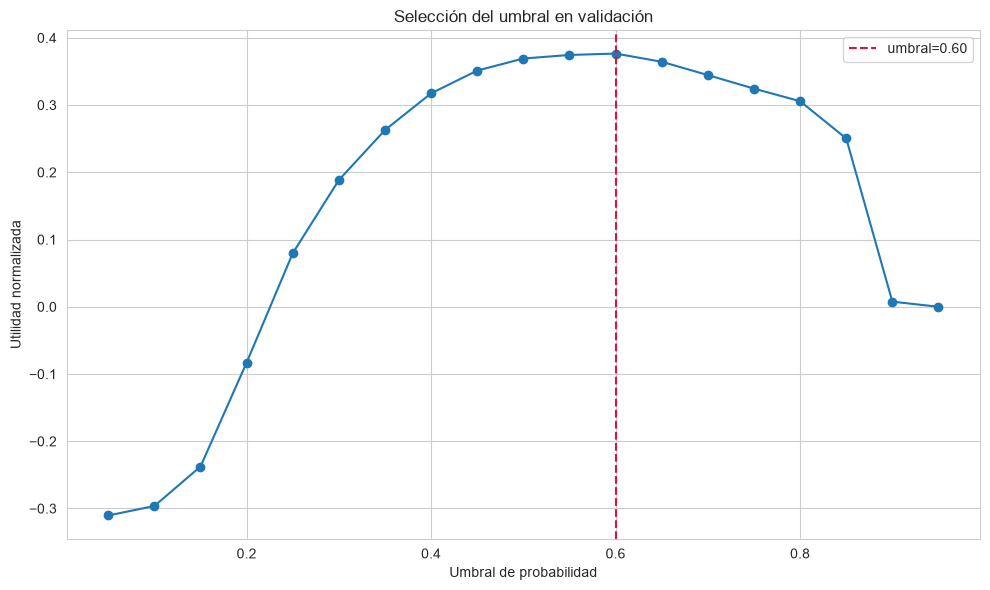

In [10]:
# Ajustamos la mejor configuración Optuna con todos los pacientes del subconjunto de entrenamiento.
best_params = dict(study.best_params)
best_class_weight = best_params.pop("class_weight")
modelo_final = crear_modelo(best_params, class_weight=best_class_weight)
modelo_final.fit(X_train[selected_features], y_train)
prob_val_final = probabilidad_positiva(modelo_final, X_val[selected_features])

# La búsqueda del umbral maximiza la métrica temporal en validación, no en B.
threshold_grid = np.round(np.arange(0.05, 1.00, 0.05), 2)
threshold_results = []
for threshold in threshold_grid:
    metrics, _ = evaluar_reto(
        y_val, prob_val_final, groups_val, threshold=float(threshold)
    )
    threshold_results.append(metrics)
threshold_table = pd.DataFrame(threshold_results)
best_index = int(threshold_table["utility_normalized"].idxmax())
best_threshold = float(threshold_table.loc[best_index, "threshold"])
validation_metrics = threshold_results[best_index]
threshold_table.to_csv(REPORTS_DIR / "threshold_validation.csv", index=False)
print(f"Umbral elegido: {best_threshold:.2f}")
print("Validación:", {
    key: round(validation_metrics[key], 4)
    for key in ("utility_normalized", "f1", "precision", "recall", "auroc", "auprc")
})

# Graficamos sensibilidad del score al umbral antes de congelar la decisión.
plt.plot(threshold_table["threshold"], threshold_table["utility_normalized"], marker="o")
plt.axvline(best_threshold, color="crimson", linestyle="--", label=f"umbral={best_threshold:.2f}")
plt.xlabel("Umbral de probabilidad")
plt.ylabel("Utilidad normalizada")
plt.title("Selección del umbral en validación")
plt.legend()
plt.tight_layout()
plt.show()

## Evaluación externa en la cohorte pública B

Congelamos ahora modelo y umbral. Calculamos una única evaluación final sobre `training_setB`, con el score temporal del reto y métricas horarias complementarias. Este resultado mide generalización entre las cohortes públicas A y B; no debe presentarse como la puntuación oficial en el test oculto ni como evidencia clínica.

In [11]:
# Aplicamos la decisión ya fijada sin reentrenar ni volver a optimizar sobre la cohorte B.
prob_test = probabilidad_positiva(modelo_final, X_test[selected_features])
test_metrics, test_predictions = evaluar_reto(
    y_test,
    prob_test,
    groups_test,
    threshold=best_threshold,
)
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
print("Métricas horarias en cohorte B:")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")
print("Matriz de confusión [no-sepsis, sepsis]:")
print(cm)

Métricas horarias en cohorte B:
utility_normalized: 0.2526
utility_observed: -5667.6167
utility_inaction: -10245.1111
utility_best: 7875.4444
threshold: 0.6000
accuracy: 0.9123
f1: 0.1151
precision: 0.0671
recall: 0.4032
auroc: 0.7215
auprc: 0.0631
Matriz de confusión [no-sepsis, sepsis]:
[[690808  60407]
 [  6433   4347]]


## Resultados, figura y artefactos reproducibles

Guardamos el reporte en `reports/physionet_challenge_2019/`, el gráfico y el modelo/configuración en las carpetas estándar del proyecto. El archivo de configuración registra versión de datos, cohortes, variables y política de separación para que el resultado no pierda su contexto.

           modelo         particion  utility_normalized       f1    auprc   recall
             base        validacion            0.024727 0.047357 0.093698 0.028897
     class_weight        validacion            0.379169 0.123927 0.103456 0.611208
feature_selection        validacion            0.379415 0.125086 0.100601 0.607122
    optuna_umbral        validacion            0.376530 0.153413 0.103814 0.524518
    optuna_umbral cohorte_B_externa            0.252613 0.115100 0.063083 0.403247


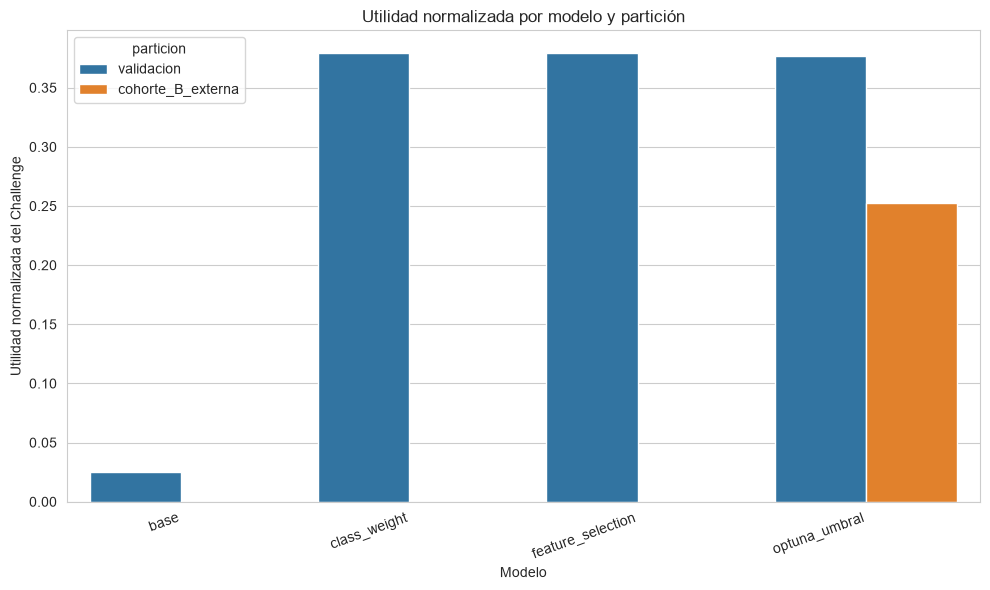

Reporte: C:\Users\marco\ml-demo1-profesor\reports\physionet_challenge_2019\metricas.csv
Búsqueda de umbral: C:\Users\marco\ml-demo1-profesor\reports\physionet_challenge_2019\threshold_validation.csv
Figura: C:\Users\marco\ml-demo1-profesor\reports\physionet_challenge_2019\figures\utilidad_modelos.png
Modelo: C:\Users\marco\ml-demo1-profesor\models\physionet_sepsis_pipeline.pkl
Configuración: C:\Users\marco\ml-demo1-profesor\reports\physionet_challenge_2019\config.json


In [12]:
# Consolidamos referencias de validación y evaluación externa en un CSV.
comparison_rows = []
for name in ("base", "class_weight", "feature_selection"):
    row = {"modelo": name, "particion": "validacion", **metricas_validacion[name]}
    comparison_rows.append(row)
comparison_rows.append(
    {"modelo": "optuna_umbral", "particion": "validacion", **validation_metrics}
)
comparison_rows.append(
    {"modelo": "optuna_umbral", "particion": "cohorte_B_externa", **test_metrics}
)
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(REPORTS_DIR / "metricas.csv", index=False)
print(comparison[["modelo", "particion", "utility_normalized", "f1", "auprc", "recall"]].to_string(index=False))

# Graficamos solo utilidad, la métrica principal del reto.
plot_data = comparison.loc[
    comparison["particion"].isin(["validacion", "cohorte_B_externa"])
]
ax = sns.barplot(
    data=plot_data,
    x="modelo",
    y="utility_normalized",
    hue="particion",
)
ax.set_title("Utilidad normalizada por modelo y partición")
ax.set_xlabel("Modelo")
ax.set_ylabel("Utilidad normalizada del Challenge")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "utilidad_modelos.png", dpi=160, bbox_inches="tight")
plt.show()

# Guardamos modelo y configuración suficiente para interpretar la evaluación.
model_path = MODELS_DIR / "physionet_sepsis_pipeline.pkl"
joblib.dump(modelo_final, model_path)
config = {
    "paper_doi": "10.1097/CCM.0000000000004145",
    "dataset_doi_version_1": "10.13026/v64v-d857",
    "dataset_doi_latest": "10.13026/0y7p-s471",
    "seed": SEED,
    "development_cohort": "training_setA",
    "external_public_cohort": "training_setB",
    "official_hidden_test_available": False,
    "selected_features": selected_features,
    "optuna_best_params": study.best_params,
    "optuna_best_utility_cv_mean": float(study.best_value),
    "optuna_trials": N_TRIALS,
    "cv_splits": N_SPLITS,
    "search_patient_cap": MAX_SEARCH_PATIENTS,
    "threshold": best_threshold,
    "challenge_utility_validation": validation_metrics["utility_normalized"],
    "challenge_utility_cohort_B": test_metrics["utility_normalized"],
    "clinical_use": "educational_only_not_for_clinical_decisions",
    "model_path": str(model_path.relative_to(PROJECT_ROOT)),
}
with (REPORTS_DIR / "config.json").open("w", encoding="utf-8") as file:
    json.dump(config, file, indent=2, ensure_ascii=False)
print(f"Reporte: {REPORTS_DIR / 'metricas.csv'}")
print(f"Búsqueda de umbral: {REPORTS_DIR / 'threshold_validation.csv'}")
print(f"Figura: {FIGURES_DIR / 'utilidad_modelos.png'}")
print(f"Modelo: {model_path}")
print(f"Configuración: {REPORTS_DIR / 'config.json'}")

## Interpretación responsable y límites

- La etiqueta Sepsis-3 se construyó con datos clínicos retrospectivos; patrones de medición, sitio hospitalario y datos faltantes pueden producir sesgos.
- La validación entre A y B es útil, pero no equivale a evaluación temporal prospectiva, validación externa independiente ni ensayo clínico.
- El umbral es consecuencia de una función de utilidad específica del reto. No es una recomendación para decisiones reales.
- Los resultados dependen del split, los recursos, la versión del código y del dataset; por eso guardamos semillas, cohortes y métricas.
- La reproducción de la clasificación del reto requeriría las predicciones y etiquetas del test oculto, que no está disponible en este dataset público.

**Conclusión:** transferimos lo aprendido en Bloque 2 a un problema longitudinal y desbalanceado, preservando la unidad paciente y la función de evaluación original. Un score experimental no demuestra seguridad ni utilidad clínica.

In [13]:
# Mensaje final con rutas relativas al repositorio para facilitar la revisión.
print("PipelinePrueba completado. Revisa reports/physionet_challenge_2019/metricas.csv,")
print("reports/physionet_challenge_2019/config.json y models/physionet_sepsis_pipeline.pkl")

PipelinePrueba completado. Revisa reports/physionet_challenge_2019/metricas.csv,
reports/physionet_challenge_2019/config.json y models/physionet_sepsis_pipeline.pkl
